# Elevator simulation

A simulation of a multiple elevators operating efficiently in a tall busy building

In [50]:
# parameteric inputs
nFloors = 50
nPassengerIds = 1000
capacityPerElevator = 10
nElevators = 4

# program params
input_data_fn = "input.csv"
elevator_position_history_fn = "out/elevator_positions_log.csv"
summary_stats_fn = "out/passenger_summary_stats.csv"

nTimeSteps = 0 # will be set based on input data length


In [51]:
# imports
import pandas as pd
import statistics
import matplotlib.pyplot as plt

# built-ins
from typing import List, Literal, TypedDict

In [52]:
# load input data
input_data = pd.read_csv(input_data_fn)

nTimeSteps = int(input_data.iloc[-1, 0])
print("number of time steps:", nTimeSteps)

# print(input_data)


number of time steps: 999


In [53]:
# validate input parameters
assert nFloors > 0, "Number of floors must be positive"
assert nPassengerIds > 0, "Number of passenger IDs must be positive"
assert capacityPerElevator > 0, "Capacity per elevator must be positive"
assert nElevators > 0, "Number of elevators must be positive"
assert nTimeSteps > 0, "Number of time steps must be positive"

In [54]:
# initialise the elevator position output data structure
elevator_position_history = pd.DataFrame({
    "time": range(nTimeSteps),
    **{f"elevator{i}": [0] * nTimeSteps for i in range(nElevators)}, # assumption: all elevators start on floor 0
}, dtype=int)

elevator_position_history.to_csv(elevator_position_history_fn, index=False)

In [55]:
# a typesafe dict data structure for keeping track of active elevator requests
class ElevatorRequest(TypedDict):
    time: int
    passenger_id: str
    source: int
    dest: int
    status: Literal["waiting", "travelling"]
    elevator: int | None

active_requests: list[ElevatorRequest] = []

# a data structure for keeping track of elevator states
ElevatorStatus = Literal["STOPPED", "RISING", "FALLING"]
class Elevator(TypedDict):
    status: ElevatorStatus
    occupants: int
    floor: int

elevatorStates: list[list[Elevator]] = []

# a dictionary to keep track of wait times for each passenger
wait_times: dict[str, list[int]] = {}


In [ ]:
### strategies

# this strategy does nothing and always returns floor 0
def strategy_nop() -> list[Elevator]:
    """Create the initial stopped state for each elevator."""
    return [Elevator(floor=0, occupants=0, status="STOPPED") for _ in range(nElevators)]


# this strategy naively scans up and down the elevator shafts (from floor 0 to nFloors-1) and picks up/drops off passengers as it goes
def strategy_scan(
    currentElevatorStates: list[Elevator],
    active_requests: list[ElevatorRequest],
) -> list[Elevator]:
    """Move elevators between the ground and top floors."""

    # move the elevators up or down depending on their current RISING/FALLING status:
    nextElevatorStates: list[Elevator] = []
    for currentElevatorState in currentElevatorStates:
        nextElevatorState = currentElevatorState.copy()
        if nextElevatorState["status"] == "FALLING":
            nextElevatorState["floor"] -= 1
            if nextElevatorState["floor"] == 0:
                nextElevatorState["status"] = "RISING"
        else:
            nextElevatorState["floor"] += 1
            if nextElevatorState["floor"] == nFloors - 1:
                nextElevatorState["status"] = "FALLING"
            else:
                nextElevatorState["status"] = "RISING"
        nextElevatorStates.append(nextElevatorState)

    # Now process passenger stops, pausing each elevator for at most one step
    elevators_to_pause: set[int] = set()
    for request in active_requests:
        if request["status"] == "waiting":
            # Assign the nearest elevator, but do not mark the passenger aboard yet
            elevator_index = min(
                range(nElevators),
                key=lambda i: abs(currentElevatorStates[i]["floor"] - request["source"]),
            )
            request["elevator"] = elevator_index
            if currentElevatorStates[elevator_index]["floor"] == request["source"]:
                if nextElevatorStates[elevator_index]["occupants"] < capacityPerElevator:
                    request["status"] = "travelling"
                    elevators_to_pause.add(elevator_index)
                    nextElevatorStates[elevator_index]["occupants"] += 1
                else:
                    print(f"{t}: Elevator {elevator_index} is full, cannot pick up passenger {request['passenger_id']}")
        elif request["status"] == "travelling":
            elevator_index = request["elevator"]
            if elevator_index is not None and currentElevatorStates[elevator_index]["floor"] == request["dest"]:
                elevators_to_pause.add(elevator_index)
                nextElevatorStates[elevator_index]["occupants"] -= 1
                active_requests.remove(request)
                # wait_times stats (passenger has reached their destination):
                if request["passenger_id"] not in wait_times:
                    wait_times[request["passenger_id"]] = []
                wait_times[request["passenger_id"]].append(t - request["time"])
                
    # Hold at the current floor once - several passengers can board/exit during the same epoch
    for elevator_index in elevators_to_pause:
        nextElevatorStates[elevator_index]["floor"] = currentElevatorStates[elevator_index]["floor"]
        # print(nextElevatorStates[elevator_index]["occupants"])

    return nextElevatorStates


# this strategy (less naively) assigns the nearest elevator to each waiting passenger and picks up/drops off passengers as it goes. Elevators stop moving when not needed.
def strategy_intelligent(
    currentElevatorStates: list[Elevator],
    active_requests: list[ElevatorRequest],
) -> list[Elevator]:
    """Move elevators between the ground and top floors."""

    # move the elevators (pause, up, down) from their current positions (currentElevatorStates)depending on the demand (using active_requests only):
    nextElevatorStates: list[Elevator] = []
    for currentElevatorState in currentElevatorStates:
        nextElevatorState = currentElevatorState.copy()
        if currentElevatorState["occupants"] == 0:
            nextElevatorState["status"] = "PAUSED"
        nextElevatorStates.append(nextElevatorState)
        

    # Now process passenger stops, pausing each elevator for at most one step
    elevators_to_pause: set[int] = set()
    for request in active_requests:
        if request["status"] == "waiting":
            # Assign the nearest elevator, but do not mark the passenger aboard yet
            elevator_index = min(
                range(nElevators),
                key=lambda i: abs(currentElevatorStates[i]["floor"] - request["source"]),
            )
            request["elevator"] = elevator_index
            if currentElevatorStates[elevator_index]["floor"] == request["source"]:
                if nextElevatorStates[elevator_index]["occupants"] < capacityPerElevator:
                    request["status"] = "travelling"
                    elevators_to_pause.add(elevator_index)
                    nextElevatorStates[elevator_index]["occupants"] += 1
                else:
                    print(f"{t}: Elevator {elevator_index} is full, cannot pick up passenger {request['passenger_id']}")
        elif request["status"] == "travelling":
            elevator_index = request["elevator"]
            if elevator_index is not None and currentElevatorStates[elevator_index]["floor"] == request["dest"]:
                elevators_to_pause.add(elevator_index)
                nextElevatorStates[elevator_index]["occupants"] -= 1
                active_requests.remove(request)
                # wait_times stats (passenger has reached their destination):
                if request["passenger_id"] not in wait_times:
                    wait_times[request["passenger_id"]] = []
                wait_times[request["passenger_id"]].append(t - request["time"])
                
    # Hold at the current floor once - several passengers can board/exit during the same epoch
    for elevator_index in elevators_to_pause:
        nextElevatorStates[elevator_index]["floor"] = currentElevatorStates[elevator_index]["floor"]
        # print(nextElevatorStates[elevator_index]["occupants"])

    return nextElevatorStates

In [57]:
wait_times.clear()
currentElevatorStates: list[Elevator] = [Elevator(floor=0, occupants=0, status="STOPPED") for _ in range(nElevators)]
nextElevatorStates: list[Elevator] = []

# loop through the input data and position the elevators efficiently
for t in range(nTimeSteps):
    # Record the elevator positions at the start of this epoch.
    elevatorStates.append([state.copy() for state in currentElevatorStates])

    # is there a request in this epoch?
    if t in input_data["time"].values:
        requests_at_t = input_data[input_data["time"] == t]
        for _, row in requests_at_t.iterrows():
            passenger_id = row["passenger_id"]
            active_requests.append({ # any existing request for a passengerwill be overwritten
                "time": row["time"],
                "passenger_id": row["passenger_id"],
                "source": row["source"],
                "dest": row["dest"],
                "status": "waiting",
                "elevator": None
            })
    
    # # Always update elevator positions for time t
    # for elevator in range(nElevators):
    
    # no-op strategy: keep elevators at floor 0 for now
    # nextElevatorStates = strategy_nop()

    # naive scan
    nextElevatorStates = strategy_scan(currentElevatorStates, active_requests)

    # Advance to the next epoch's elevator positions.
    currentElevatorStates = nextElevatorStates

elevator_position_history = pd.DataFrame(
    [[elevator["floor"] for elevator in states] for states in elevatorStates],
    columns=[f"elevator_{i}" for i in range(nElevators)]
)
elevator_position_history.to_csv(elevator_position_history_fn, index=False)
print(elevator_position_history)

# print(currentElevatorStates)

212: Elevator 1 is full, cannot pick up passenger passenger388
212: Elevator 1 is full, cannot pick up passenger passenger788
300: Elevator 3 is full, cannot pick up passenger passenger538
300: Elevator 3 is full, cannot pick up passenger passenger632
302: Elevator 3 is full, cannot pick up passenger passenger437
303: Elevator 3 is full, cannot pick up passenger passenger935
304: Elevator 3 is full, cannot pick up passenger passenger935
305: Elevator 3 is full, cannot pick up passenger passenger993
306: Elevator 3 is full, cannot pick up passenger passenger993
307: Elevator 3 is full, cannot pick up passenger passenger164
307: Elevator 3 is full, cannot pick up passenger passenger125
308: Elevator 3 is full, cannot pick up passenger passenger125
755: Elevator 2 is full, cannot pick up passenger passenger247
759: Elevator 2 is full, cannot pick up passenger passenger262
763: Elevator 2 is full, cannot pick up passenger passenger597
765: Elevator 2 is full, cannot pick up passenger passe

Summary stats for elevator wait times (including ride time)
Overall average wait time: 70.9
[min,max] wait time: [2, 268]
Overall total wait time: 18646
Assuming Gaussian distribution for wait times
Wait time standard deviation: 45.01
Wait time variance: 2025.56
Wait time median: 67
Wait time standard error: 2.78
Wait time confidence interval (95%): [65.46, 76.34]


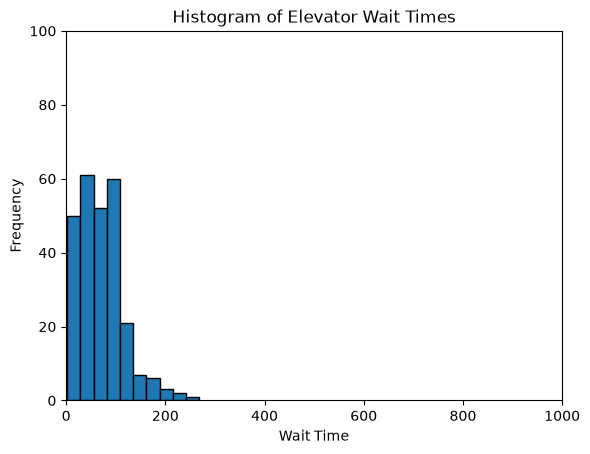

In [58]:
## summary stats
print("Summary stats for elevator wait times (including ride time)")

# print per-passenger summary stats: 
# for passenger_id, times in sorted(wait_times.items()):
#     print(f"Passenger {passenger_id}\n\twait times: {times}")
#     if times:
#         print(f"\taverage wait time: {sum(times) / len(times)}")
#         print(f"\ttotal wait time: {sum(times)}")

# print overall summary stats
total_wait_times = [sum(times) for times in wait_times.values() if times]
if total_wait_times:
    print(f"Overall average wait time: {round(sum(total_wait_times) / len(total_wait_times), 2)}")
    print(f"[min,max] wait time: [{min(total_wait_times)}, {max(total_wait_times)}]")
    print(f"Overall total wait time: {sum(total_wait_times)}")

# other notable stats about time distributsions/system behaviour:
print("Assuming Gaussian distribution for wait times")
if total_wait_times:
    print(f"Wait time standard deviation: {round(statistics.stdev(total_wait_times), 2)}")
    print(f"Wait time variance: {round(statistics.variance(total_wait_times), 2)}")
    print(f"Wait time median: {round(statistics.median(total_wait_times), 2)}")
    print(f"Wait time standard error: {round(statistics.stdev(total_wait_times) / (len(total_wait_times) ** 0.5), 2)}")
    print(f"Wait time confidence interval (95%): [{round(statistics.mean(total_wait_times) - 1.96 * (statistics.stdev(total_wait_times) / (len(total_wait_times) ** 0.5)), 2)}, {round(statistics.mean(total_wait_times) + 1.96 * (statistics.stdev(total_wait_times) / (len(total_wait_times) ** 0.5)), 2)}]")

# draw a histogram
if total_wait_times:
    plt.hist(total_wait_times, bins=10, edgecolor='black')
    plt.title("Histogram of Elevator Wait Times")
    plt.xlabel("Wait Time")
    plt.ylabel("Frequency")
    plt.xlim(0, 1000)
    plt.ylim(0,100)
    plt.show()